### K-Means Clustering

Implementation of K-Means clustering on a basketball dataset using three distance metrics: Euclidean, Manhattan, and Minkowski.

- Custom K-Means implementation.
- Clustering for K = 1, 2, 3, 4.
- Cluster visualization with centroids.
- SSE calculation for each iteration.
- Elbow method to compare the optimal number of clusters.

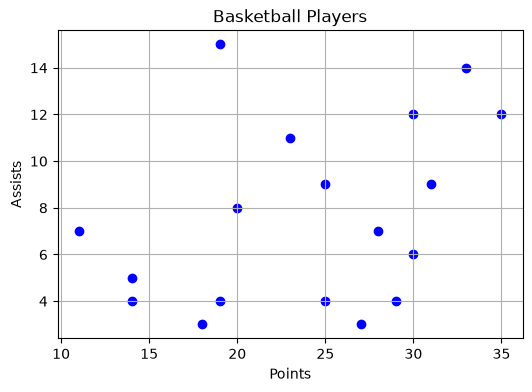


EUCLIDEAN DISTANCE


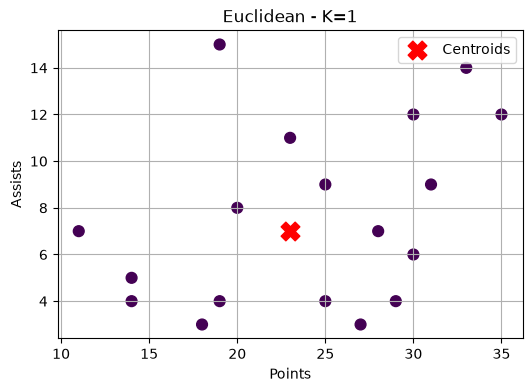


K = 1: SSE by iteration
Iteration 1: Cluster SSE = [3101], Total SSE = 3101.00
Iteration 2: Cluster SSE = [1377], Total SSE = 1377.00


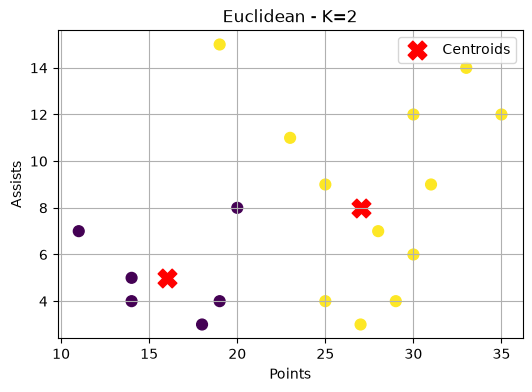


K = 2: SSE by iteration
Iteration 1: Cluster SSE = [  66 2469], Total SSE = 2535.00
Iteration 2: Cluster SSE = [159 626], Total SSE = 785.00
Iteration 3: Cluster SSE = [119 508], Total SSE = 627.00


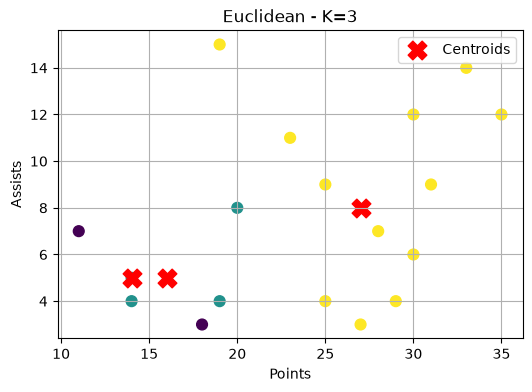


K = 3: SSE by iteration
Iteration 1: Cluster SSE = [ 66 121 688], Total SSE = 875.00
Iteration 2: Cluster SSE = [ 34  67 508], Total SSE = 609.00


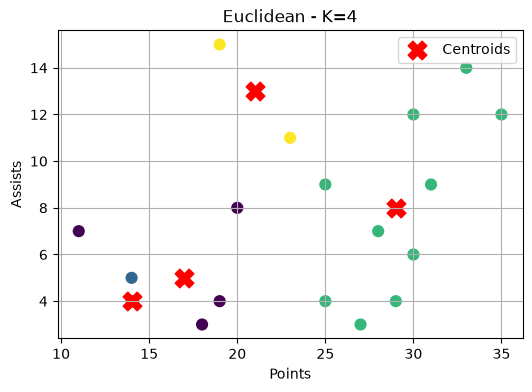


K = 4: SSE by iteration
Iteration 1: Cluster SSE = [ 66 103 504  99], Total SSE = 772.00
Iteration 2: Cluster SSE = [ 60   7 333  83], Total SSE = 483.00
Iteration 3: Cluster SSE = [ 82   3 307  39], Total SSE = 431.00
Iteration 4: Cluster SSE = [ 70   3 307  17], Total SSE = 397.00


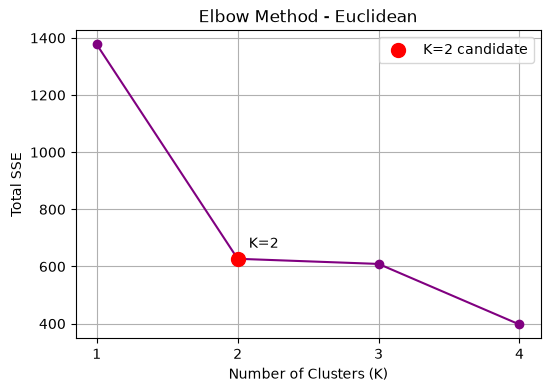


Final SSE Table - Euclidean
 K  Total SSE
 1       1377
 2        627
 3        609
 4        397

MANHATTAN DISTANCE


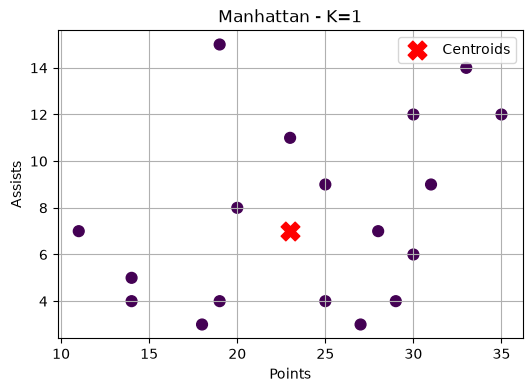


K = 1: SSE by iteration
Iteration 1: Cluster SSE = [3101], Total SSE = 3101.00
Iteration 2: Cluster SSE = [1377], Total SSE = 1377.00


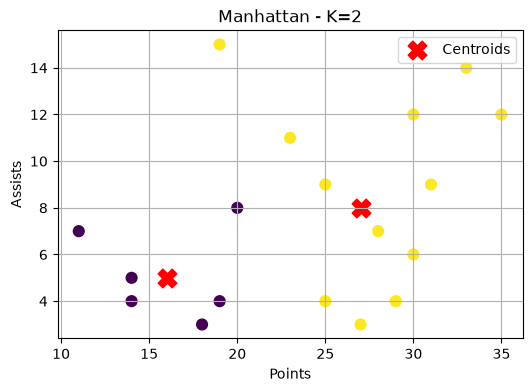


K = 2: SSE by iteration
Iteration 1: Cluster SSE = [   0 2542], Total SSE = 2542.00
Iteration 2: Cluster SSE = [213 726], Total SSE = 939.00
Iteration 3: Cluster SSE = [119 508], Total SSE = 627.00


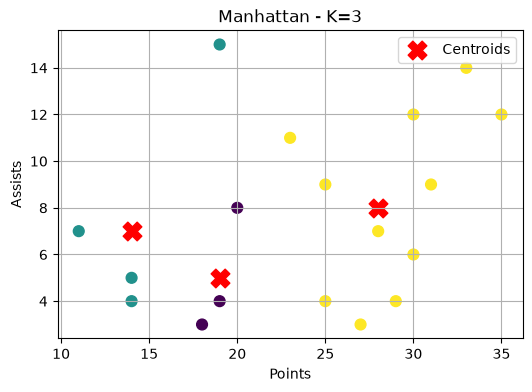


K = 3: SSE by iteration
Iteration 1: Cluster SSE = [  0 483 411], Total SSE = 894.00
Iteration 2: Cluster SSE = [  3 225 368], Total SSE = 596.00
Iteration 3: Cluster SSE = [ 33 147 368], Total SSE = 548.00
Iteration 4: Cluster SSE = [ 18 147 368], Total SSE = 533.00


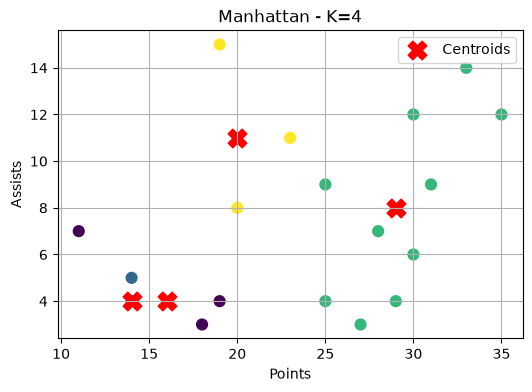


K = 4: SSE by iteration
Iteration 1: Cluster SSE = [  0 280 411  99], Total SSE = 790.00
Iteration 2: Cluster SSE = [ 69  29 333  83], Total SSE = 514.00
Iteration 3: Cluster SSE = [ 49   3 307  73], Total SSE = 432.00


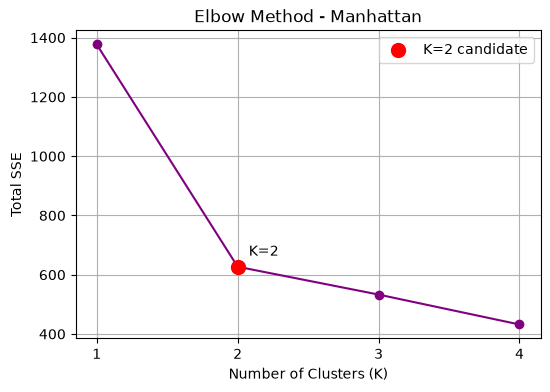


Final SSE Table - Manhattan
 K  Total SSE
 1       1377
 2        627
 3        533
 4        432

MINKOWSKI DISTANCE


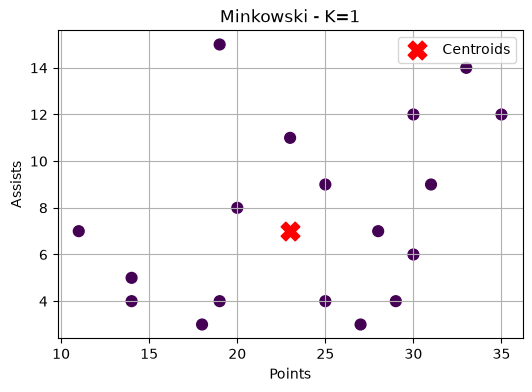


K = 1: SSE by iteration
Iteration 1: Cluster SSE = [3101], Total SSE = 3101.00
Iteration 2: Cluster SSE = [1377], Total SSE = 1377.00


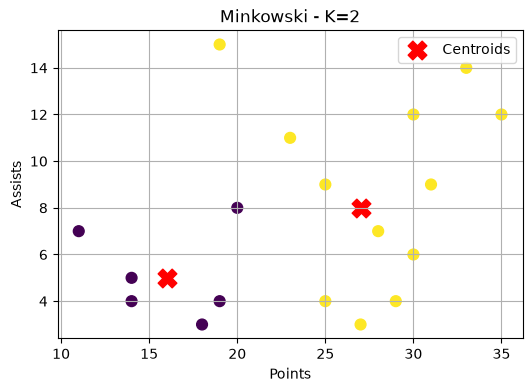


K = 2: SSE by iteration
Iteration 1: Cluster SSE = [  66 2469], Total SSE = 2535.00
Iteration 2: Cluster SSE = [159 626], Total SSE = 785.00
Iteration 3: Cluster SSE = [119 508], Total SSE = 627.00


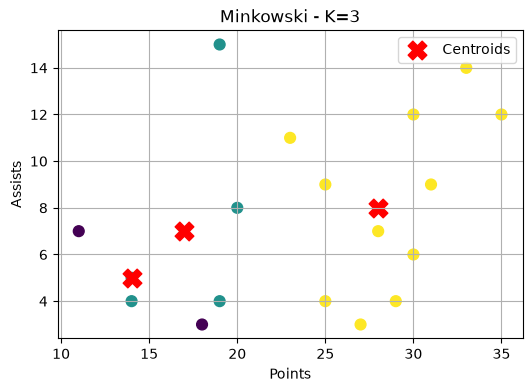


K = 3: SSE by iteration
Iteration 1: Cluster SSE = [ 66 306 504], Total SSE = 876.00
Iteration 2: Cluster SSE = [ 34 167 368], Total SSE = 569.00


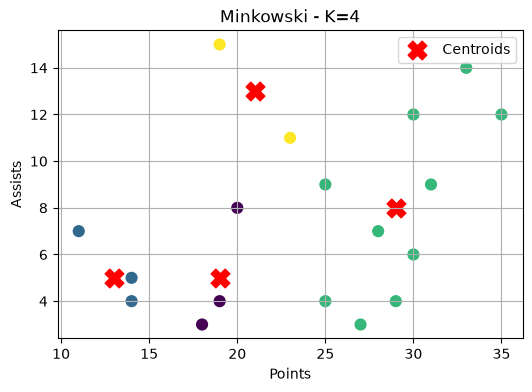


K = 4: SSE by iteration
Iteration 1: Cluster SSE = [ 66 103 504  99], Total SSE = 772.00
Iteration 2: Cluster SSE = [ 60   7 333  83], Total SSE = 483.00
Iteration 3: Cluster SSE = [ 82   3 307  39], Total SSE = 431.00
Iteration 4: Cluster SSE = [ 30  46 307  17], Total SSE = 400.00
Iteration 5: Cluster SSE = [ 18  31 307  17], Total SSE = 373.00


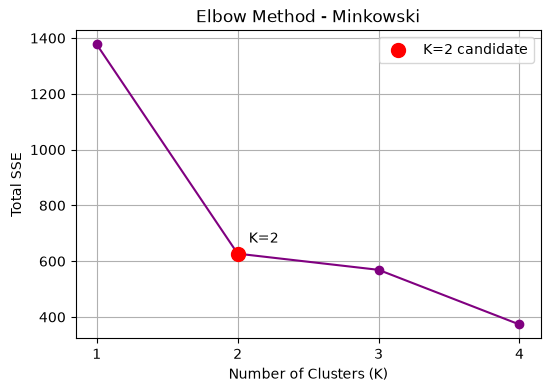


Final SSE Table - Minkowski
 K  Total SSE
 1       1377
 2        627
 3        569
 4        373


In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Data
df = pd.DataFrame({
    'Points': [18, 19, 14, 14, 11, 20, 28, 30, 31,
               35, 33, 25, 25, 27, 29, 30, 19, 23],
    'Assists': [3, 4, 5, 4, 7, 8, 7, 6, 9, 12, 14,
                9, 4, 3, 4, 12, 15, 11],
    'Rebounds': [15, 14, 10, 8, 14, 13, 9, 5, 4,
                 11, 6, 5, 3, 8, 12, 7, 6, 5]
})

X = df.values


# Step 1: Distance between points and centroids
def compute_distance(X, centroids, metric='euclidean', p=3):
    distances = np.zeros((len(X), len(centroids)))

    for i in range(len(centroids)):
        diff = X - centroids[i]

        if metric == 'euclidean':
            distances[:, i] = np.sqrt(np.sum(diff**2, axis=1))
        elif metric == 'manhattan':
            distances[:, i] = np.sum(np.abs(diff), axis=1)
        else:
            distances[:, i] = np.sum(
                np.abs(diff)**p, axis=1
            )**(1/p)

    return distances


# Step 2: K-means clustering
def custom_kmeans(X, K, metric='euclidean', p=3, max_iters=100, seed=42):

    np.random.seed(seed)
    idx = np.random.choice(len(X), K, replace=False)
    centroids = X[idx].copy()

    history = []
    labels = np.zeros(len(X), dtype=int)

    for iteration in range(max_iters):

        distances = compute_distance(X, centroids, metric, p)
        labels = np.argmin(distances, axis=1)
        cluster_sse = []
        for i in range(K):
            cluster_points = X[labels == i]
            if len(cluster_points) > 0:
                sse = np.sum((cluster_points - centroids[i])**2)
            else:
                sse = 0

            cluster_sse.append(sse)

        total_sse = sum(cluster_sse)

        history.append({
            'Iteration': iteration + 1,
            'Cluster SSE': cluster_sse.copy(),
            'Total SSE': total_sse
        })

        new_centroids = centroids.copy()

        for i in range(K):
            cluster_points = X[labels == i]

            if len(cluster_points) > 0:
                new_centroids[i] = np.mean(cluster_points, axis=0)

        if np.allclose(centroids, new_centroids):
            centroids = new_centroids
            break

        centroids = new_centroids

    distances = compute_distance(X, centroids, metric, p)
    labels = np.argmin(distances, axis=1)

    return labels, centroids, history


# Step 3: Original scatter plot
# Visualizes Points vs Assists; Rebounds is still used in clustering.
plt.figure(figsize=(6, 4))
plt.scatter(df['Points'], df['Assists'], color='blue')
plt.xlabel('Points')
plt.ylabel('Assists')
plt.title('Basketball Players')
plt.grid(True)
plt.show()


# Step 4: Run K = 1, 2, 3, 4 for each metric
metrics = ['euclidean', 'manhattan', 'minkowski']
k_range = [1, 2, 3, 4]

for metric in metrics:

    print(f"\n{'=' * 40}")
    print(f"{metric.upper()} DISTANCE")

    sse_values = []

    for K in k_range:

        labels, centroids, history = custom_kmeans(
            X, K, metric=metric, p=3
        )

        # Plot clusters in 2D
        plt.figure(figsize=(6, 4))

        plt.scatter(
            X[:, 0], X[:, 1],
            c=labels, cmap='viridis', s=60
        )

        plt.scatter(
            centroids[:, 0], centroids[:, 1],
            color='red', marker='X', s=180,
            label='Centroids'
        )

        plt.xlabel('Points')
        plt.ylabel('Assists')
        plt.title(f'{metric.capitalize()} - K={K}')
        plt.grid(True)
        plt.legend()
        plt.show()

        # Print SSE for every iteration
        print(f"\nK = {K}: SSE by iteration")

        for entry in history:
            print(
                f"Iteration {entry['Iteration']}: "
                f"Cluster SSE = "
                f"{np.round(entry['Cluster SSE'], 2)}, "
                f"Total SSE = {entry['Total SSE']:.2f}"
            )

        final_sse = history[-1]['Total SSE']
        sse_values.append(final_sse)

    # Step 5: Elbow plot
    plt.figure(figsize=(6, 4))
    plt.plot(
        k_range, sse_values,
        marker='o', color='purple'
    )

    # Mark K=2 as a candidate, not a guaranteed optimum
    plt.scatter(
        [2], [sse_values[1]],
        color='red', s=100, zorder=3,
        label='K=2 candidate'
    )

    plt.annotate(
        'K=2',
        (2, sse_values[1]),
        xytext=(8, 8),
        textcoords='offset points'
    )

    plt.xlabel('Number of Clusters (K)')
    plt.ylabel('Total SSE')
    plt.title(f'Elbow Method - {metric.capitalize()}')
    plt.xticks(k_range)
    plt.grid(True)
    plt.legend()
    plt.show()

    # Summary table
    print(f"\nFinal SSE Table - {metric.capitalize()}")

    print(pd.DataFrame({
        'K': k_range,
        'Total SSE': np.round(sse_values, 2)
    }).to_string(index=False))
